In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

file_path = (
    project_root / "data" / "processed"
    / "coffee_shop_sales_clean.csv"
)

reports_dir = project_root / "reports"
reports_dir.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(
    file_path,
    parse_dates=["transaction_date"]
)

print("=== DATASET PENJUALAN PUBLIK ===")
print("Jumlah record:", len(df))
print("Jumlah kolom:", len(df.columns))

display(df.head())

=== DATASET PENJUALAN PUBLIK ===
Jumlah record: 149116
Jumlah kolom: 16


,transaction_id,transaction_date,transaction_time,transaction_qty,store_id,store_location,product_id,unit_price,product_category,product_type,product_detail,total_amount,category_group,data_type,source_dataset,source_platform
0,1,2023-01-01,07:06:11,2,5,Lower Manhattan,32,3.0,Coffee,Gourmet brewed coffee,Ethiopia Rg,6.0,beverage,public,Coffee Shop Sales,Kaggle
1,2,2023-01-01,07:08:56,2,5,Lower Manhattan,57,3.1,Tea,Brewed Chai tea,Spicy Eye Opener Chai Lg,6.2,beverage,public,Coffee Shop Sales,Kaggle
2,3,2023-01-01,07:14:04,2,5,Lower Manhattan,59,4.5,Drinking Chocolate,Hot chocolate,Dark chocolate Lg,9.0,beverage,public,Coffee Shop Sales,Kaggle
3,4,2023-01-01,07:20:24,1,5,Lower Manhattan,22,2.0,Coffee,Drip coffee,Our Old Time Diner Blend Sm,2.0,beverage,public,Coffee Shop Sales,Kaggle
4,5,2023-01-01,07:22:41,2,5,Lower Manhattan,57,3.1,Tea,Brewed Chai tea,Spicy Eye Opener Chai Lg,6.2,beverage,public,Coffee Shop Sales,Kaggle


In [2]:
print("=== VALIDASI DATA EDA ===")

assert df["data_type"].eq("public").all()
assert df["transaction_date"].notna().all()
assert (df["transaction_qty"] > 0).all()
assert (df["unit_price"] > 0).all()

expected_amount = (
    df["transaction_qty"] * df["unit_price"]
)

assert (
    (df["total_amount"] - expected_amount).abs() < 0.011
).all(), "Nilai transaksi tidak konsisten!"

print("Jumlah record:", len(df))
print("Rentang tanggal:",
      df["transaction_date"].min().date(),
      "sampai",
      df["transaction_date"].max().date())

print("Validasi dasar berhasil!")

=== VALIDASI DATA EDA ===
Jumlah record: 149116
Rentang tanggal: 2023-01-01 sampai 2023-06-30
Validasi dasar berhasil!


In [3]:
print("=== INDIKATOR PENJUALAN DATASET PUBLIK ===")

total_sales = df["total_amount"].sum()
total_records = len(df)
total_units = df["transaction_qty"].sum()
unique_products = df["product_id"].nunique()

print(f"Total nilai penjualan: {total_sales:,.2f}")
print(f"Jumlah record transaksi: {total_records:,}")
print(f"Total unit terjual: {total_units:,}")
print(f"Jumlah produk unik (product_id): {unique_products:,}")

=== INDIKATOR PENJUALAN DATASET PUBLIK ===
Total nilai penjualan: 698,812.33
Jumlah record transaksi: 149,116
Total unit terjual: 214,470
Jumlah produk unik (product_id): 80


In [4]:
print("=== ANALISIS PENJUALAN BULANAN ===")

df["month"] = df["transaction_date"].dt.to_period("M")

monthly_sales = (
    df.groupby("month")
    .agg(
        total_sales=("total_amount", "sum"),
        total_units=("transaction_qty", "sum"),
        total_records=("transaction_id", "count")
    )
    .reset_index()
)

monthly_sales["month"] = (
    monthly_sales["month"].astype(str)
)

display(monthly_sales)

=== ANALISIS PENJUALAN BULANAN ===


,month,total_sales,total_units,total_records
0,2023-01,81677.74,24870,17314
1,2023-02,76145.19,23550,16359
2,2023-03,98834.68,30406,21229
3,2023-04,118941.08,36469,25335
4,2023-05,156727.76,48233,33527
5,2023-06,166485.88,50942,35352


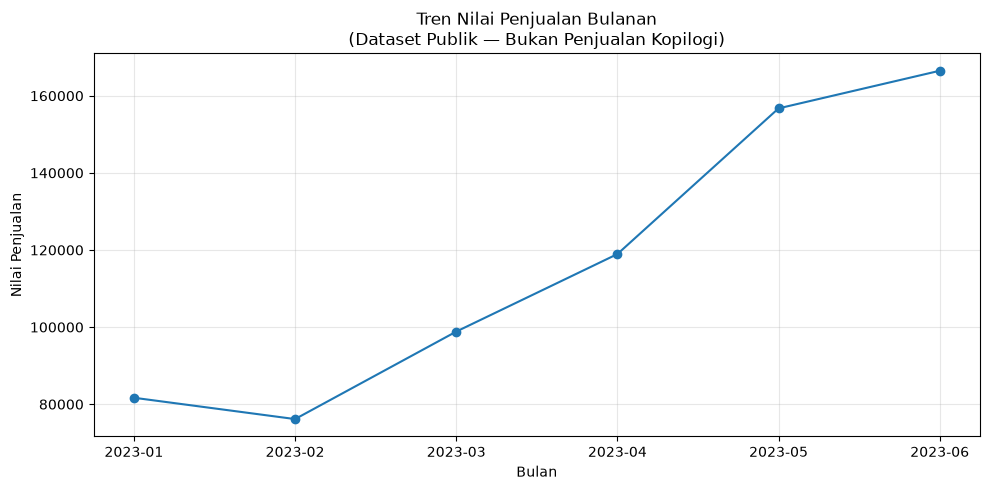

In [5]:
plt.figure(figsize=(10, 5))

plt.plot(
    monthly_sales["month"],
    monthly_sales["total_sales"],
    marker="o"
)

plt.title(
    "Tren Nilai Penjualan Bulanan\n"
    "(Dataset Publik — Bukan Penjualan Kopilogi)"
)

plt.xlabel("Bulan")
plt.ylabel("Nilai Penjualan")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [6]:
print("=== ANALISIS PENJUALAN PER KATEGORI ===")

category_sales = (
    df.groupby("product_category")
    .agg(
        total_sales=("total_amount", "sum"),
        total_units=("transaction_qty", "sum"),
        total_records=("transaction_id", "count")
    )
    .sort_values("total_sales", ascending=False)
    .reset_index()
)

category_sales["sales_percentage"] = (
    category_sales["total_sales"]
    / category_sales["total_sales"].sum() * 100
).round(2)

display(category_sales)

=== ANALISIS PENJUALAN PER KATEGORI ===


,product_category,total_sales,total_units,total_records,sales_percentage
0,Coffee,269952.45,89250,58416,38.63
1,Tea,196405.95,69737,45449,28.11
2,Bakery,82315.64,23214,22796,11.78
3,Drinking Chocolate,72416.00,17457,11468,10.36
4,Coffee beans,40085.25,1828,1753,5.74
5,Branded,13607.00,776,747,1.95
6,Loose Tea,11213.60,1210,1210,1.60
7,Flavours,8408.80,10511,6790,1.20
8,Packaged Chocolate,4407.64,487,487,0.63


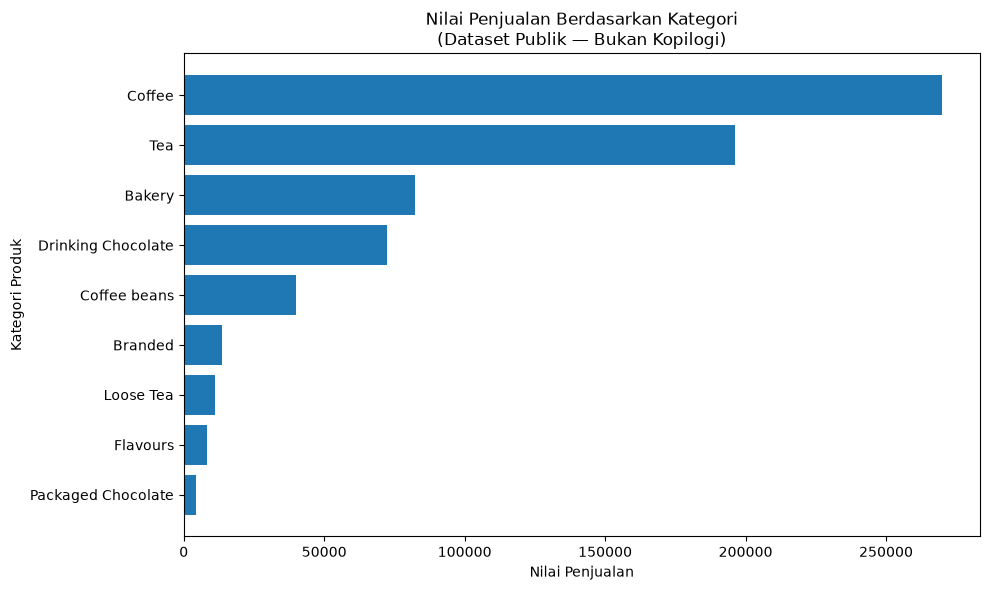

In [7]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.barh(
    category_sales["product_category"],
    category_sales["total_sales"]
)

plt.gca().invert_yaxis()

plt.title(
    "Nilai Penjualan Berdasarkan Kategori\n"
    "(Dataset Publik — Bukan Kopilogi)"
)

plt.xlabel("Nilai Penjualan")
plt.ylabel("Kategori Produk")

plt.tight_layout()
plt.show()

In [8]:
print("=== ANALISIS PENJUALAN PER LOKASI ===")

store_sales = (
    df.groupby("store_location")
    .agg(
        total_sales=("total_amount", "sum"),
        total_units=("transaction_qty", "sum"),
        total_records=("transaction_id", "count")
    )
    .sort_values("total_sales", ascending=False)
    .reset_index()
)

display(store_sales)

=== ANALISIS PENJUALAN PER LOKASI ===


,store_location,total_sales,total_units,total_records
0,Hell's Kitchen,236511.17,71737,50735
1,Astoria,232243.91,70991,50599
2,Lower Manhattan,230057.25,71742,47782


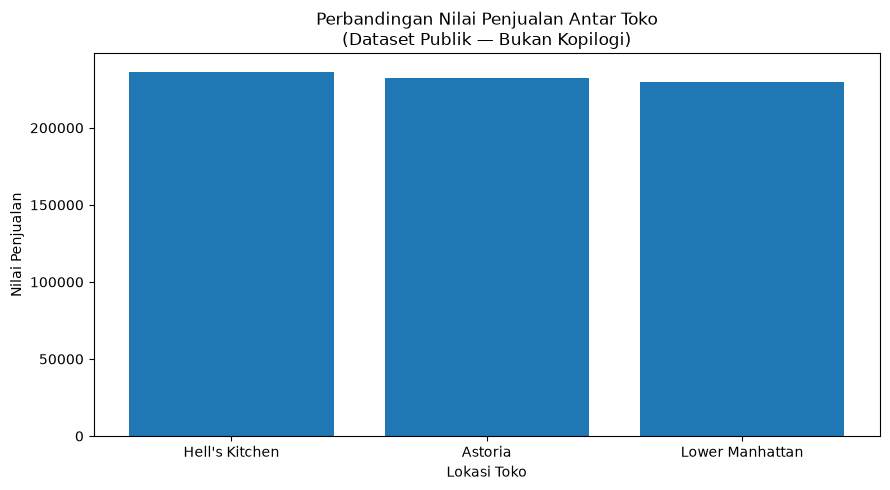

In [9]:
plt.figure(figsize=(9, 5))

plt.bar(
    store_sales["store_location"],
    store_sales["total_sales"]
)

plt.title(
    "Perbandingan Nilai Penjualan Antar Toko\n"
    "(Dataset Publik — Bukan Kopilogi)"
)

plt.xlabel("Lokasi Toko")
plt.ylabel("Nilai Penjualan")

plt.tight_layout()
plt.show()

In [10]:
print("=== 10 PRODUK DENGAN NILAI PENJUALAN TERTINGGI ===")

top_products = (
    df.groupby(
        ["product_id", "product_detail"]
    )
    .agg(
        total_sales=("total_amount", "sum"),
        total_units=("transaction_qty", "sum"),
        total_records=("transaction_id", "count")
    )
    .sort_values("total_sales", ascending=False)
    .head(10)
    .reset_index()
)

display(top_products)

=== 10 PRODUK DENGAN NILAI PENJUALAN TERTINGGI ===


,product_id,product_detail,total_sales,total_units,total_records
0,61,Sustainably Grown Organic Lg,21151.75,4453,2961
1,59,Dark chocolate Lg,21006.00,4668,3029
2,39,Latte Rg,19112.25,4497,2896
3,41,Cappuccino Lg,17641.75,4151,2772
4,55,Morning Sunrise Chai Lg,17384.00,4346,2830
5,38,Latte,17257.50,4602,2990
6,36,Jamaican Coffee River Lg,16481.25,4395,2911
7,60,Sustainably Grown Organic Rg,16233.75,4329,2842
8,40,Cappuccino,15997.50,4266,2793
9,27,Brazilian Lg,15109.50,4317,2771


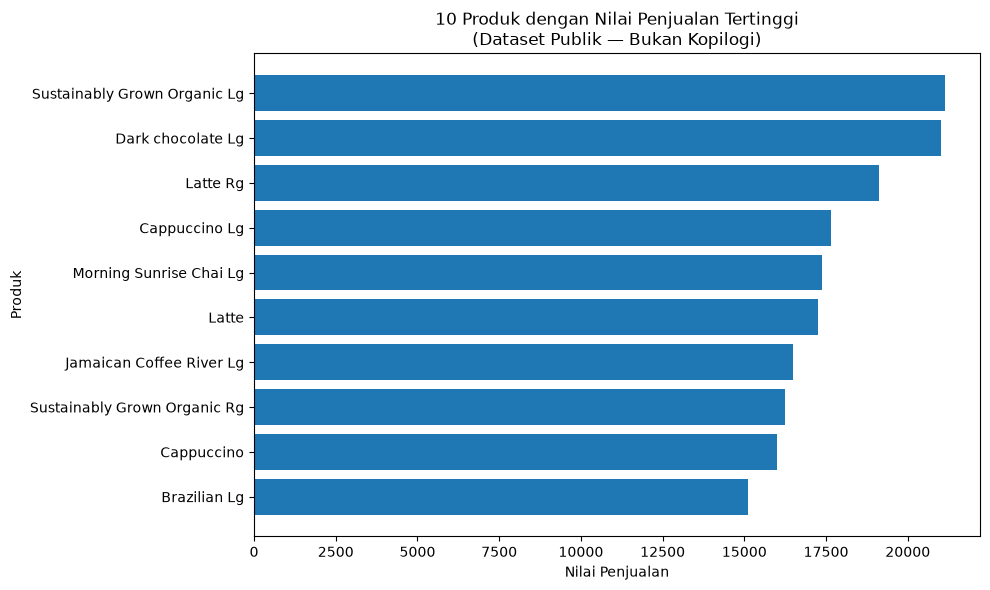

In [11]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.barh(
    top_products["product_detail"],
    top_products["total_sales"]
)

plt.gca().invert_yaxis()

plt.title(
    "10 Produk dengan Nilai Penjualan Tertinggi\n"
    "(Dataset Publik — Bukan Kopilogi)"
)

plt.xlabel("Nilai Penjualan")
plt.ylabel("Produk")

plt.tight_layout()
plt.show()

In [12]:
print("=== ANALISIS TRANSAKSI BERDASARKAN JAM ===")

# Mengambil jam dari waktu transaksi
df["transaction_hour"] = pd.to_datetime(
    df["transaction_time"],
    format="%H:%M:%S",
    errors="coerce"
).dt.hour

print(
    "Waktu tidak valid:",
    df["transaction_hour"].isna().sum()
)

hourly_activity = (
    df.groupby("transaction_hour")
    .agg(
        total_records=("transaction_id", "count"),
        total_units=("transaction_qty", "sum"),
        total_sales=("total_amount", "sum")
    )
    .reset_index()
)

display(hourly_activity)

=== ANALISIS TRANSAKSI BERDASARKAN JAM ===
Waktu tidak valid: 0


,transaction_hour,total_records,total_units,total_sales
0,6,4594,6865,21900.27
1,7,13428,19449,63526.47
2,8,17654,25197,82699.87
3,9,17764,25370,85169.53
4,10,18545,26713,88673.39
5,11,9766,14035,46319.14
6,12,8708,12690,40192.79
7,13,8714,12439,40367.45
8,14,8933,12907,41304.74
9,15,8979,12923,41733.10


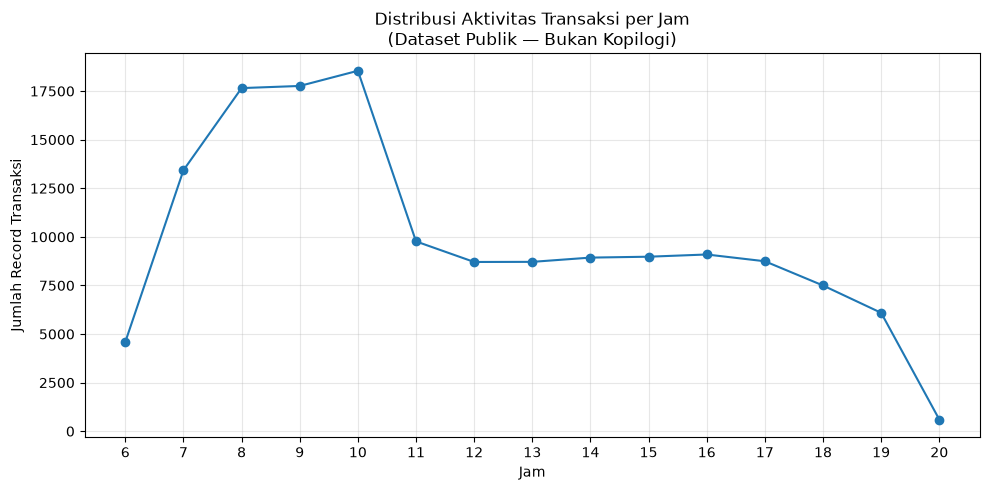

In [13]:
plt.figure(figsize=(10, 5))

plt.plot(
    hourly_activity["transaction_hour"],
    hourly_activity["total_records"],
    marker="o"
)

plt.title(
    "Distribusi Aktivitas Transaksi per Jam\n"
    "(Dataset Publik — Bukan Kopilogi)"
)

plt.xlabel("Jam")
plt.ylabel("Jumlah Record Transaksi")
plt.xticks(hourly_activity["transaction_hour"])
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [14]:
print("=== MENYIMPAN HASIL SALES EDA ===")

reports_dir.mkdir(parents=True, exist_ok=True)

outputs = {
    "sales_monthly_summary.csv": monthly_sales,
    "sales_category_summary.csv": category_sales,
    "sales_store_summary.csv": store_sales,
    "sales_top_products.csv": top_products,
    "sales_hourly_activity.csv": hourly_activity
}

for filename, dataframe in outputs.items():
    output_path = reports_dir / filename

    dataframe.to_csv(
        output_path,
        index=False,
        encoding="utf-8-sig"
    )

    print("Tersimpan:", filename)

print("\nSeluruh tabel hasil EDA berhasil disimpan.")

=== MENYIMPAN HASIL SALES EDA ===
Tersimpan: sales_monthly_summary.csv
Tersimpan: sales_category_summary.csv
Tersimpan: sales_store_summary.csv
Tersimpan: sales_top_products.csv
Tersimpan: sales_hourly_activity.csv

Seluruh tabel hasil EDA berhasil disimpan.


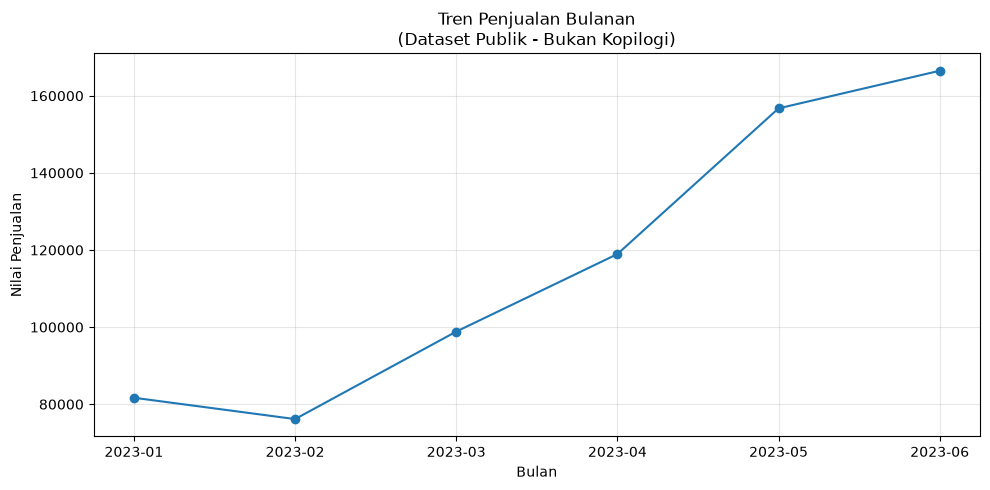

In [15]:
# Grafik tren bulanan
plt.figure(figsize=(10, 5))

plt.plot(
    monthly_sales["month"],
    monthly_sales["total_sales"],
    marker="o"
)

plt.title(
    "Tren Penjualan Bulanan\n"
    "(Dataset Publik - Bukan Kopilogi)"
)

plt.xlabel("Bulan")
plt.ylabel("Nilai Penjualan")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    reports_dir / "sales_monthly_trend.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()